In [89]:
import os
os.environ["OMP_NUM_THREADS"] = "16"
import warnings

warnings.filterwarnings("ignore", category=UserWarning, module="sklearn.cluster._kmeans")


In [90]:
import multiprocessing
print(multiprocessing.cpu_count())

16


In [4]:
# Standard library
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Sklearn
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.preprocessing import KBinsDiscretizer, OneHotEncoder, StandardScaler
from sklearn.base import clone, is_classifier, is_regressor
from sklearn.linear_model import LogisticRegression, LinearRegression
from sklearn.neighbors import KNeighborsClassifier, KNeighborsRegressor
from sklearn.svm import SVC
from sklearn.impute import SimpleImputer
from sklearn.tree import DecisionTreeClassifier, DecisionTreeRegressor
from sklearn.ensemble import RandomForestClassifier, RandomForestRegressor
from sklearn.metrics import r2_score, accuracy_score, mean_absolute_error, mean_squared_error


wq_class_df = pd.read_csv("datasets/winequality-red.csv", delimiter=";")
wq_reg_df = pd.read_csv("datasets/winequality-red.csv", delimiter=";")
bc_df = pd.read_csv("datasets/Breast-Cancer-Wisconsin-(Diagnostic)-Data-Set.csv").drop(columns=["id"])
ch_df = pd.read_csv("datasets/california-housing-data.csv")
db_df = pd.read_excel("datasets/Dry_Bean_Dataset.xlsx")
asn_df = pd.read_csv("datasets/AirfoilSelfNoise.csv")


dataset_names = ["bc", "wq_class", "ch", "db", "asn", "wq_reg"]
dataset_dfs = [bc_df, wq_class_df, ch_df, db_df, asn_df, wq_reg_df]
datasets = dict(zip(dataset_names, dataset_dfs))
task_type = {"bc": "classification", "wq_class": "classification", "ch": "regression", "db": "classification", "asn": "regression", "wq_reg": "regression"}
pd.set_option("display.max_rows", 20)

datasets["db"]


,Area,Perimeter,MajorAxisLength,MinorAxisLength,AspectRation,Eccentricity,ConvexArea,EquivDiameter,Extent,Solidity,roundness,Compactness,ShapeFactor1,ShapeFactor2,ShapeFactor3,ShapeFactor4,Class
0,28395,610.291,208.178117,173.888747,1.197191,0.549812,28715,190.141097,0.763923,0.988856,0.958027,0.913358,0.007332,0.003147,0.834222,0.998724,SEKER
1,28734,638.018,200.524796,182.734419,1.097356,0.411785,29172,191.272750,0.783968,0.984986,0.887034,0.953861,0.006979,0.003564,0.909851,0.998430,SEKER
2,29380,624.110,212.826130,175.931143,1.209713,0.562727,29690,193.410904,0.778113,0.989559,0.947849,0.908774,0.007244,0.003048,0.825871,0.999066,SEKER
3,30008,645.884,210.557999,182.516516,1.153638,0.498616,30724,195.467062,0.782681,0.976696,0.903936,0.928329,0.007017,0.003215,0.861794,0.994199,SEKER
4,30140,620.134,201.847882,190.279279,1.060798,0.333680,30417,195.896503,0.773098,0.990893,0.984877,0.970516,0.006697,0.003665,0.941900,0.999166,SEKER
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
13606,42097,759.696,288.721612,185.944705,1.552728,0.765002,42508,231.515799,0.714574,0.990331,0.916603,0.801865,0.006858,0.001749,0.642988,0.998385,DERMASON
13607,42101,757.499,281.576392,190.713136,1.476439,0.735702,42494,231.526798,0.799943,0.990752,0.922015,0.822252,0.006688,0.001886,0.676099,0.998219,DERMASON
13608,42139,759.321,281.539928,191.187979,1.472582,0.734065,42569,231.631261,0.729932,0.989899,0.918424,0.822730,0.006681,0.001888,0.676884,0.996767,DERMASON
13609,42147,763.779,283.382636,190.275731,1.489326,0.741055,42667,231.653248,0.705389,0.987813,0.907906,0.817457,0.006724,0.001852,0.668237,0.995222,DERMASON


In [92]:
for name, df in datasets.items():
    numeric_cols = df.select_dtypes(include=['number']).columns
    non_numeric_cols = df.columns.difference(numeric_cols)
    
    print(f"{name}: {len(non_numeric_cols)} non-numeric features")
    if len(non_numeric_cols) > 0:
        print(f"  - {list(non_numeric_cols)}")


bc: 1 non-numeric features
  - ['diagnosis']
wq_class: 0 non-numeric features
ch: 1 non-numeric features
  - ['ocean_proximity']
db: 1 non-numeric features
  - ['Class']
asn: 0 non-numeric features
wq_reg: 0 non-numeric features


In [93]:
datasets["ch"].select_dtypes(include=['object', 'category']).columns

Index(['ocean_proximity'], dtype='object')

In [94]:
datasets["ch"].count()

longitude             20640
latitude              20640
housing_median_age    20640
total_rooms           20640
total_bedrooms        20433
population            20640
households            20640
median_income         20640
median_house_value    20640
ocean_proximity       20640
dtype: int64

In [95]:
models = {
    "logreg": LogisticRegression(max_iter=10000), 
    "svc": SVC(), 
    "dt": DecisionTreeClassifier(), 
    "knc": KNeighborsClassifier(),
    "rfc": RandomForestClassifier(),
    "linreg": LinearRegression(),
    "dtr": DecisionTreeRegressor(),
    "knr": KNeighborsRegressor(),
    "rfr": RandomForestRegressor(n_jobs=16)
    }

trees = ["dt", "dtr", "rfc", "rfr"]

precision_values = {
    "rounding": [-2,-1,0,1,2,3], 
    "uniform": [2,3,4,5,6], 
    "quantile": [2,3,4,5,6], 
    "kmeans": [2,3,4,5,6], 
    "sig figs": [1,2,3,4,5,6]
    }

modes = ["both", "training_data_only", "testing_data_only"]

metrics = {
    "classification": {"accuracy": accuracy_score},
    "regression": {"mae": mean_absolute_error, "r2": r2_score, "mse": mean_squared_error}
}

In [96]:

def handle_missing(X):
    X = X.copy()

    return X.dropna().reset_index()

In [97]:

for name, dataset in datasets.items():

    if dataset.isna().any().any():
        datasets[name] = handle_missing(dataset)

datasets["ch"].isna().sum().sum()

np.int64(0)

In [98]:
datasets["ch"].count()


index                 20433
longitude             20433
latitude              20433
housing_median_age    20433
total_rooms           20433
total_bedrooms        20433
population            20433
households            20433
median_income         20433
median_house_value    20433
ocean_proximity       20433
dtype: int64

In [99]:
target_columns = {
    "bc": "diagnosis",
    "wq_class": "quality", 
    "ch": "median_house_value",
    "db": "Class",
    "asn": "SSPL",
    "wq_reg": "quality"
}

X = {}
for name in dataset_names:
    X[name] = datasets[name].drop(columns=[target_columns[name]])

y = {}
for name in dataset_names:
    y[name] = datasets[name][target_columns[name]]

X["asn"]


,f,alpha,c,U_infinity,delta
0,800,0.0,0.3048,71.3,0.002663
1,1000,0.0,0.3048,71.3,0.002663
2,1250,0.0,0.3048,71.3,0.002663
3,1600,0.0,0.3048,71.3,0.002663
4,2000,0.0,0.3048,71.3,0.002663
...,...,...,...,...,...
1498,2500,15.6,0.1016,39.6,0.052849
1499,3150,15.6,0.1016,39.6,0.052849
1500,4000,15.6,0.1016,39.6,0.052849
1501,5000,15.6,0.1016,39.6,0.052849


In [100]:
def sig_fig_round(num, sig):

    if pd.isna(num):
        return num

    if not isinstance(num, (int, float, np.floating, np.integer)):
        return num

    if num == 0:
        return 0
    
    return np.round(num, sig - int(np.floor(np.log10(abs(num)))) - 1)


In [101]:
# sig_fig_round("4.2212",1)

In [102]:
splits = {}
random_state = 100
for name in X:
    X_train, X_test, y_train, y_test = train_test_split(
        X[name], y[name], train_size=0.8, random_state=random_state
    )
    
    splits[name] = {
        "X_train": X_train,
        "X_test": X_test,
        "y_train": y_train,
        "y_test": y_test
    }
splits["wq_reg"]["X_train"]

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol
382,8.3,0.260,0.42,2.0,0.080,11.0,27.0,0.99740,3.21,0.80,9.4
1034,8.9,0.745,0.18,2.5,0.077,15.0,48.0,0.99739,3.20,0.47,9.7
195,7.8,0.590,0.33,2.0,0.074,24.0,120.0,0.99680,3.25,0.54,9.4
370,6.9,0.765,0.02,2.3,0.063,35.0,63.0,0.99750,3.57,0.78,9.9
427,9.5,0.780,0.22,1.9,0.077,6.0,32.0,0.99880,3.26,0.56,10.6
...,...,...,...,...,...,...,...,...,...,...,...
53,8.6,0.380,0.36,3.0,0.081,30.0,119.0,0.99700,3.20,0.56,9.4
350,10.7,0.670,0.22,2.7,0.107,17.0,34.0,1.00040,3.28,0.98,9.9
79,8.3,0.625,0.20,1.5,0.080,27.0,119.0,0.99720,3.16,1.12,9.1
792,7.1,0.610,0.02,2.5,0.081,17.0,87.0,0.99745,3.48,0.60,9.7


In [103]:

def encode_categorical(X_train, X_test, model_name):


    cat_cols = X_train.select_dtypes(include=["object", "category"]).columns

    if len(cat_cols) == 0:
        return X_train.copy(), X_test.copy()

    if model_name not in trees:
        encoder = OneHotEncoder(drop="first")
    else:
        encoder = OneHotEncoder(drop=None)
    encoder.fit(X_train[cat_cols])

    train_cat = encoder.transform(X_train[cat_cols]).toarray()
    test_cat = encoder.transform(X_test[cat_cols]).toarray()

    new_col_names = encoder.get_feature_names_out(cat_cols)

    train_cat_df = pd.DataFrame(train_cat, columns=new_col_names, index=X_train.index)
    test_cat_df = pd.DataFrame(test_cat, columns=new_col_names, index=X_test.index)

    # print(train_cat_df)

    X_train_num = X_train.drop(columns=cat_cols)
    X_test_num = X_test.drop(columns=cat_cols)

    X_train_enc = pd.concat([X_train_num, train_cat_df], axis=1)
    X_test_enc = pd.concat([X_test_num, test_cat_df], axis=1)

    return X_train_enc, X_test_enc

In [104]:
# encode_categorical(datasets["le"], datasets["le"], "linreg")[0]


In [105]:
# encode_categorical(splits["ch"]["X_train"], splits["ch"]["X_train"], "dt")


In [2]:
def apply_transformation(X_train, X_test, method, level, mode):

    if mode not in ["both", "training_data_only", "testing_data_only"]:
        raise ValueError(f"Unknown mode: {mode}.")
    
    X_train_new, X_test_new = X_train.copy(), X_test.copy()
    
    if method == "rounding":

        if mode == "both" or mode == "training_data_only":
            X_train_new = X_train_new.round(level)
        if mode == "both" or mode == "testing_data_only":
            X_test_new = X_test_new.round(level)
            
    elif method in ["uniform", "quantile", "kmeans"]:

        if level < 2:
            raise ValueError(f"Number of bins out of range: {level}.")

        for col in X_train.columns:

            if not pd.api.types.is_numeric_dtype(X_train[col]):
                continue

            if X_train_new[col].nunique() < level:
                continue
            
            if method == "quantile":
                kbd = KBinsDiscretizer(n_bins=level, encode="ordinal", strategy=method, quantile_method="linear")
            else:
                kbd = KBinsDiscretizer(n_bins=level, encode="ordinal", strategy=method)

            kbd.fit(X_train_new[[col]])

            if mode in ["both", "training_data_only"]:
                X_train_new[col] = kbd.inverse_transform(kbd.transform(X_train_new[[col]])).ravel()

            if mode in ["both", "testing_data_only"]:
                X_test_new[col] = kbd.inverse_transform(kbd.transform(X_test_new[[col]])).ravel()

           
    elif method == "sig figs":

        if level < 1:
            raise ValueError(f"Number of significant figures out of range: {level}.")
        
        if mode == "both" or mode == "training_data_only":
            cols = X_train_new.select_dtypes(include=[np.number]).columns
            X_train_new[cols] = X_train_new[cols].map(lambda x: sig_fig_round(x, level))
        if mode == "both" or mode == "testing_data_only":
            cols = X_test_new.select_dtypes(include=[np.number]).columns
            X_test_new[cols] = X_test_new[cols].map(lambda x: sig_fig_round(x, level))

    else:
        raise ValueError(f"Unknown method: {method}.")
            
    return X_train_new, X_test_new

In [10]:

# apply_transformation(datasets["ch"], datasets["bc"], mode="training_data_only", method="rounding", level=-1)

In [107]:

def standard_scale(X_train, X_test):
    X_train_scaled = X_train.copy()
    X_test_scaled = X_test.copy()

    numeric_cols = X_train_scaled.select_dtypes(include=[np.number]).columns
    if len(numeric_cols) == 0:
        return X_train_scaled, X_test_scaled

    scaler = StandardScaler()
    X_train_scaled[numeric_cols] = scaler.fit_transform(X_train_scaled[numeric_cols])
    X_test_scaled[numeric_cols] = scaler.transform(X_test_scaled[numeric_cols])

    return X_train_scaled, X_test_scaled

In [108]:
print([list(models.items())[0]])



[('logreg', LogisticRegression(max_iter=10000))]


In [109]:
results = []

for dataset_name in [dataset_names[2]]:
    print(dataset_name)
    print(f"Processing Dataset: {dataset_name} ({task_type[dataset_name]})")

    X_train_original = splits[dataset_name]["X_train"].copy()
    X_test_original = splits[dataset_name]["X_test"].copy()

    for model_name, model in models.items():
        print(f"  - Starting {model_name}...")

        task = task_type[dataset_name]

        if task == "classification" and not is_classifier(model):
            print(f"  - Skipped {model_name}...") 
            continue

        elif task == "regression" and not is_regressor(model):
            print(f"  - Skipped {model_name}...") 
            continue



        X_train_base, X_test_base = standard_scale(X_train_original, X_test_original)
        X_train_base, X_test_base = encode_categorical(X_train_base, X_test_base, model)

        print(f"  - Running base model...") 
        # Base model
        base_model = clone(model)
        # base_cv = abs(cross_val_score(base_model, X_train_base, splits[dataset_name]["y_train"], cv=5, scoring=metric_alias).mean())
        base_model.fit(X_train_base, splits[dataset_name]["y_train"])
        base_pred = base_model.predict(X_test_base)
        data_row = {"task": task, "dataset": dataset_name, "seed": random_state, "method": "base", "model": model_name, "level": 0, "mode": "base"}

        for metric in metrics[task].keys():
            data_row[metric] = metrics[task][metric](splits[dataset_name]["y_test"], base_pred)

        results.append(data_row)
        print(f"  - Finished base model...") 
        # Experiments
        for method, levels in precision_values.items():

            print(f"   - Testing {method}...") 

            for level in levels:

                print(f"       - Applying level {level} ...") 

                for mode in modes:

                    print(f"            - Applying mode {mode} ...") 
                    
                    X_train_new, X_test_new = apply_transformation(X_train_original, X_test_original, method, level, mode)
                                        
                    X_train_new, X_test_new = standard_scale(X_train_new, X_test_new)
                    X_train_new, X_test_new = encode_categorical(X_train_new, X_test_new, model_name)
                    print(f"                    - Applied transformations...") 
                    
                    
                    exp_model = clone(model)

                    # if mode == "both":
                    #     cv_mean = abs(cross_val_score(exp_model, X_train_new, splits[dataset_name]["y_train"], cv=5, scoring=metric_alias).mean())
                    # else:
                    #     cv_mean = None

                    exp_model.fit(X_train_new, splits[dataset_name]["y_train"])

                    print(f"                    - Trained model...") 

                    exp_pred = exp_model.predict(X_test_new)
                    data_row = {"task": task, "dataset": dataset_name, "seed": random_state, "method": method, "model": model_name, "level": level, "mode": mode}

                    for metric in metrics[task].keys():
                        data_row[metric] = metrics[task][metric](splits[dataset_name]["y_test"], exp_pred)

                    results.append(data_row)
            print(f"   - Finished {method}...") 
results_df = pd.DataFrame(results)

ch
Processing Dataset: ch (regression)
  - Starting logreg...
  - Skipped logreg...
  - Starting svc...
  - Skipped svc...
  - Starting dt...
  - Skipped dt...
  - Starting knc...
  - Skipped knc...
  - Starting rfc...
  - Skipped rfc...
  - Starting linreg...
  - Running base model...
  - Finished base model...
   - Testing rounding...
       - Applying level -2 ...
            - Applying mode both ...
                    - Applied transformations...
                    - Trained model...
            - Applying mode training_data_only ...
                    - Applied transformations...
                    - Trained model...
            - Applying mode testing_data_only ...
                    - Applied transformations...
                    - Trained model...
       - Applying level -1 ...
            - Applying mode both ...
                    - Applied transformations...
                    - Trained model...
            - Applying mode training_data_only ...
                    -

In [110]:
pd.set_option("display.max_rows", None)
results_df


,task,dataset,seed,method,model,level,mode,mae,r2,mse
0,regression,ch,100,base,linreg,0,base,50988.708035,0.622813,5.048887e+09
1,regression,ch,100,rounding,linreg,-2,both,67665.814068,0.357096,8.605677e+09
2,regression,ch,100,rounding,linreg,-2,training_data_only,70858.369768,0.347477,8.734433e+09
3,regression,ch,100,rounding,linreg,-2,testing_data_only,211403.985400,-2.929465,5.259841e+10
4,regression,ch,100,rounding,linreg,-1,both,59480.037830,0.500488,6.686285e+09
5,regression,ch,100,rounding,linreg,-1,training_data_only,66709.552487,0.450415,7.356548e+09
6,regression,ch,100,rounding,linreg,-1,testing_data_only,142012.128768,-1.361752,3.161356e+10
7,regression,ch,100,rounding,linreg,0,both,52491.803000,0.605978,5.274236e+09
8,regression,ch,100,rounding,linreg,0,training_data_only,51478.775452,0.619455,5.093840e+09
9,regression,ch,100,rounding,linreg,0,testing_data_only,52510.882347,0.601690,5.331629e+09


2185208144.5327554 234893724023.8015


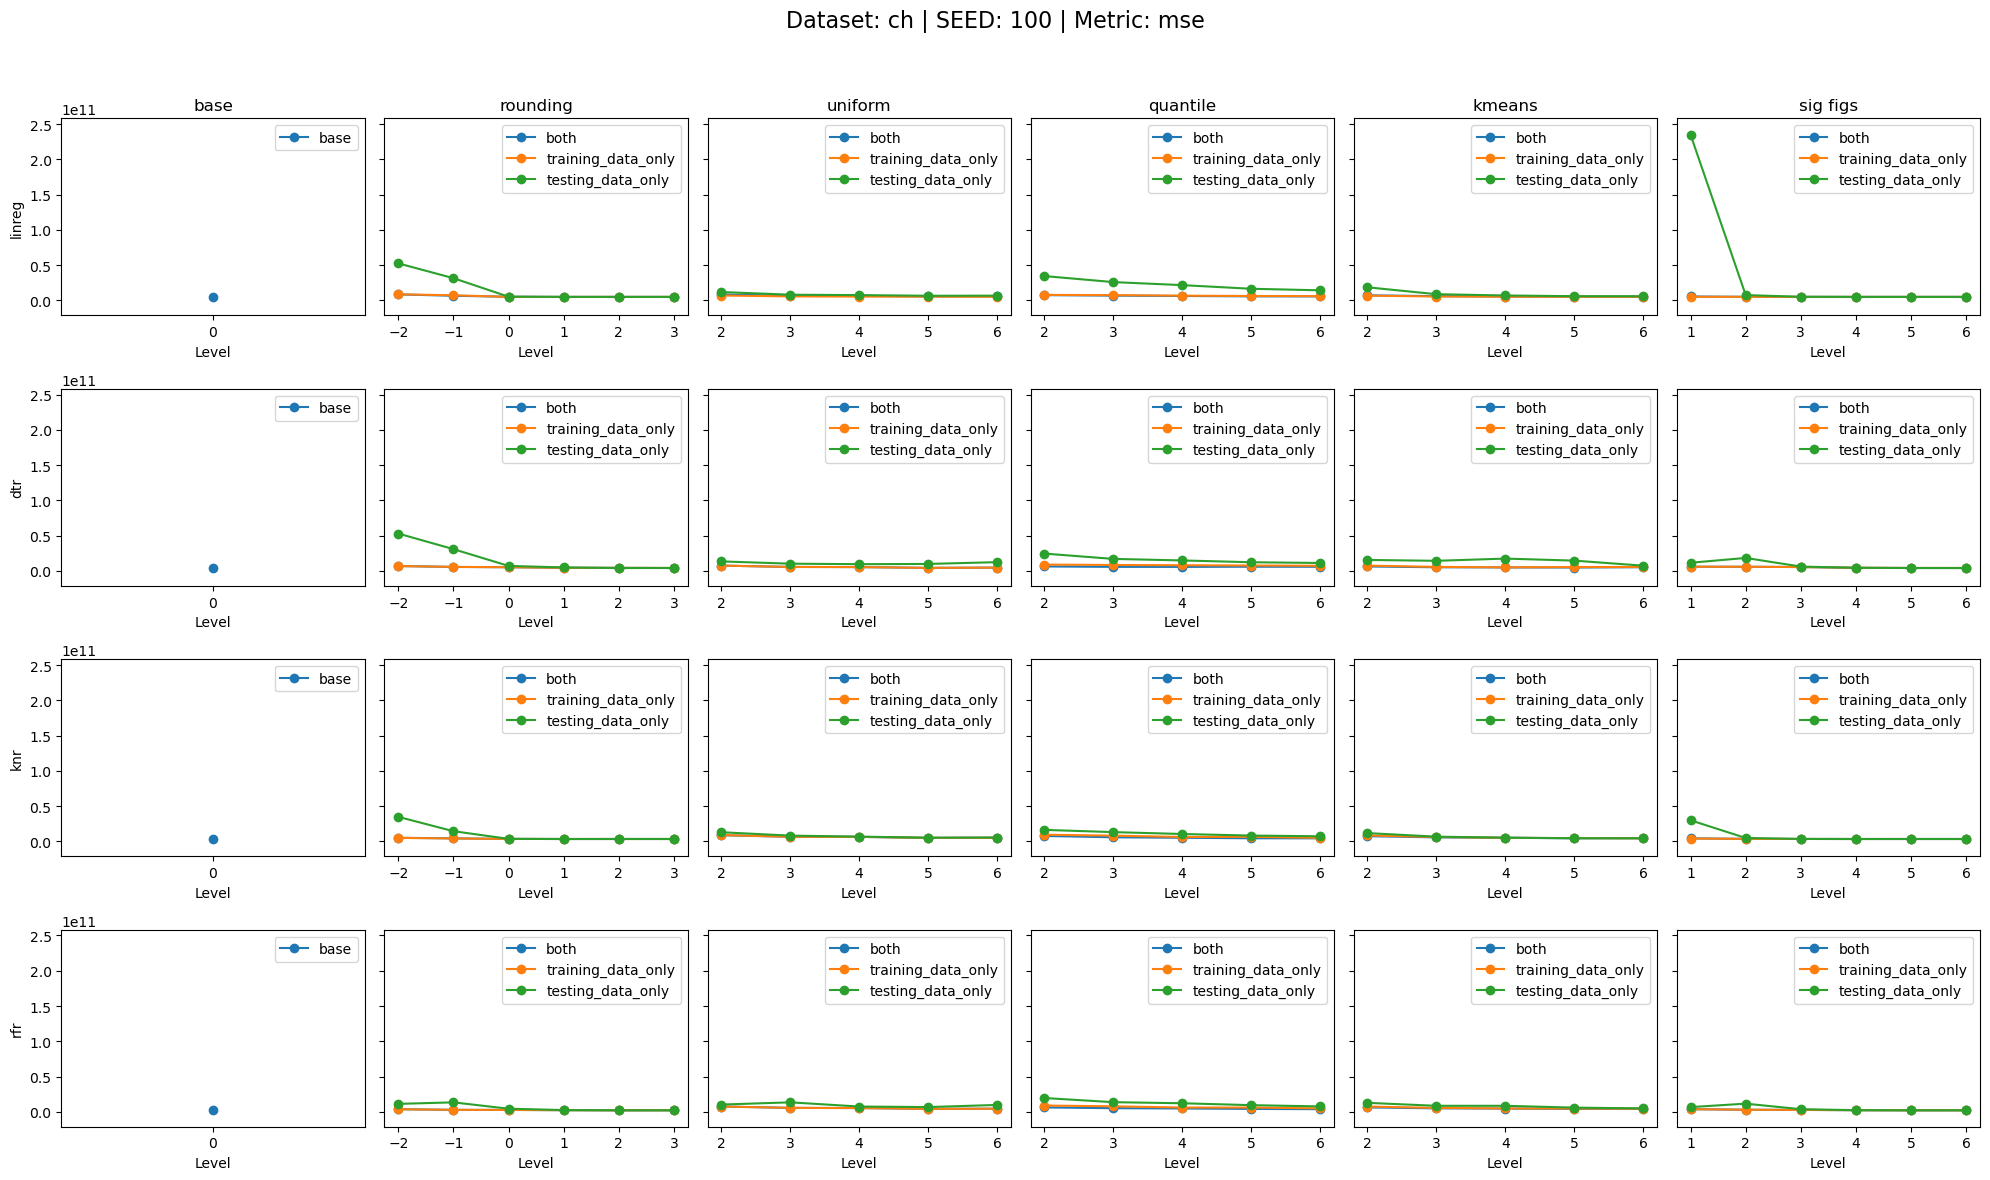

In [119]:
metric = "mse"   # change to 'accuracy', 'r2', 'mse', or 'mae'

datasets = results_df['dataset'].dropna().unique()
models = results_df['model'].dropna().unique()
methods = results_df['method'].dropna().unique()

for dataset in datasets:

    # filter once for this dataset
    df_d = results_df[
        (results_df['dataset'] == dataset) &
        (results_df[metric].notna())
    ]

    if df_d.empty:
        continue

    # decide y-limits based on metric
    if metric == 'accuracy':
        ymin, ymax = 0, 1

    elif metric == 'r2':
        data_min = df_d[metric].min()
        data_max = df_d[metric].max()
        print(data_min)

        y_range = data_max - data_min
        pad = 0.1 * y_range if y_range > 0 else 0.1

        ymin = data_min - pad
        print(ymin)
        # ymax = data_max + pad

        # optional: cap the top at 1 since R² usually doesn't exceed 1
        ymax = 1

    elif metric in ['mse', 'mae']:
        data_min = df_d[metric].min()
        data_max = df_d[metric].max()
        print(data_min,data_max)

        y_range = data_max - data_min
        pad = 0.1 * y_range if y_range > 0 else 0.1

        ymin = data_min - pad
        ymax = data_max + pad

    else:
        # fallback for any other metric
        data_min = df_d[metric].min()
        data_max = df_d[metric].max()

        y_range = data_max - data_min
        pad = 0.1 * y_range if y_range > 0 else 0.1

        ymin = data_min - pad
        ymax = data_max + pad

    fig, axes = plt.subplots(
        len(models),
        len(methods),
        figsize=(20, 12),
        sharey=True
    )

    axes = np.atleast_2d(axes)

    for i, model in enumerate(models):
        for j, method in enumerate(methods):

            ax = axes[i, j]

            subset = df_d[
                (df_d['model'] == model) &
                (df_d['method'] == method)
            ]

            if subset.empty:
                ax.set_visible(False)
                continue

            for mode in subset['mode'].dropna().unique():
                mode_data = subset[subset['mode'] == mode].sort_values('level')

                ax.plot(
                    mode_data['level'],
                    mode_data[metric],
                    marker='o',
                    label=mode
                )

            if i == 0:
                ax.set_title(method)
            if j == 0:
                ax.set_ylabel(model)

            ax.set_xlabel("Level")
            ax.set_xticks(sorted(subset['level'].dropna().unique()))
            ax.set_ylim(ymin, ymax)

            if metric == 'r2':
                ax.axhline(0, linestyle='--', linewidth=1)

            ax.legend()

    fig.suptitle(
        f"Dataset: {dataset} | SEED: {random_state} | Metric: {metric}",
        fontsize=16
    )

    plt.tight_layout(rect=[0, 0, 1, 0.95])
    plt.show()

    fig.savefig('ch_new_100_mse.png', dpi=600)

In [112]:
X_thing = np.array([[2.3],
              [5.1],
              [7.8],
              [1.2],
              [9.0],
              [4.5]])

kbd = KBinsDiscretizer(
    n_bins=3,
    encode='ordinal',      
    strategy='uniform'     
)

X_binned = kbd.fit_transform(X_thing)

print("Binned values:")
print(X_binned)

print("Bin edges:")
print(kbd.bin_edges_)
print(kbd.inverse_transform(kbd.fit_transform(X_thing)))

Binned values:
[[0.]
 [1.]
 [2.]
 [0.]
 [2.]
 [1.]]
Bin edges:
[array([1.2, 3.8, 6.4, 9. ])]
[[2.5]
 [5.1]
 [7.7]
 [2.5]
 [7.7]
 [5.1]]


In [113]:
print(os.environ.get("OMP_NUM_THREADS"))

16


In [114]:
splits["bc"]["X_train"].nunique()

radius_mean                372
texture_mean               396
perimeter_mean             425
area_mean                  434
smoothness_mean            398
compactness_mean           434
concavity_mean             433
concave points_mean        437
symmetry_mean              353
fractal_dimension_mean     406
radius_se                  440
texture_se                 417
perimeter_se               426
area_se                    426
smoothness_se              440
compactness_se             437
concavity_se               432
concave points_se          407
symmetry_se                407
fractal_dimension_se       439
radius_worst               375
texture_worst              416
perimeter_worst            417
area_worst                 439
smoothness_worst           351
compactness_worst          430
concavity_worst            437
concave points_worst       409
symmetry_worst             410
fractal_dimension_worst    438
dtype: int64

In [120]:
with pd.ExcelWriter("Project-Data.xlsx", engine="openpyxl", mode="a", if_sheet_exists="overlay") as writer:
    
    results_df.to_excel(writer, sheet_name="ch_new_5", startrow=1, header=False)

In [ ]:
# Check all datasets for missing values
for dataset_name, df in datasets.items():
    print(f"\n{'='*50}")
    print(f"Dataset: {dataset_name}")
    print(f"{'='*50}")
    
    missing_count = df.isnull().sum()
    if missing_count.sum() > 0:
        print(f"  Total missing values: {missing_count.sum()}")
        print(f"  Missing by column:\n{missing_count[missing_count > 0]}")
    else:
        print(f"  No missing values")